In [12]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import json

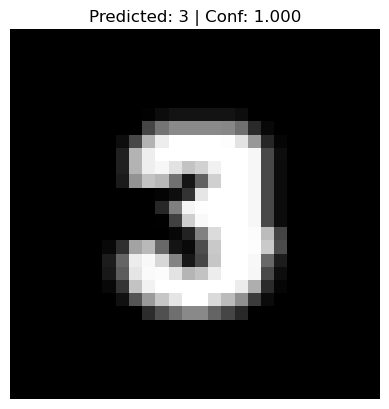

Cell 0 → Detected: 3
Probability: 1.000
-------------


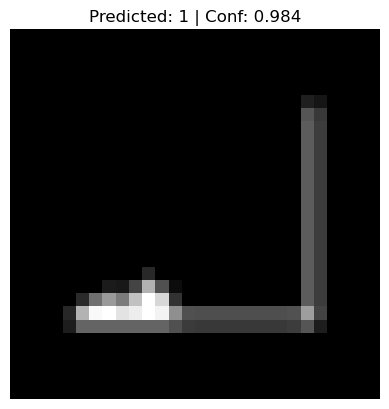

Cell 1 → Detected: 1
Probability: 0.984
-------------


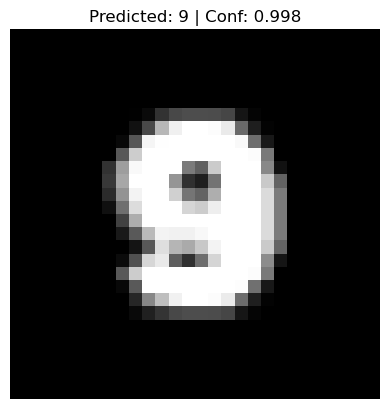

Cell 2 → Detected: 9
Probability: 0.998
-------------


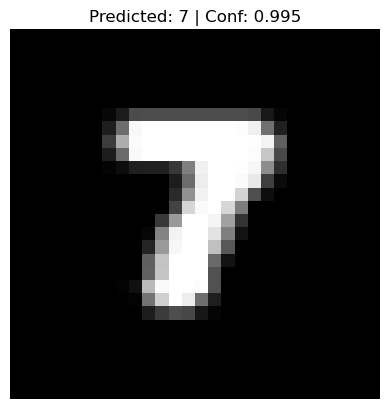

Cell 3 → Detected: 7
Probability: 0.995
-------------


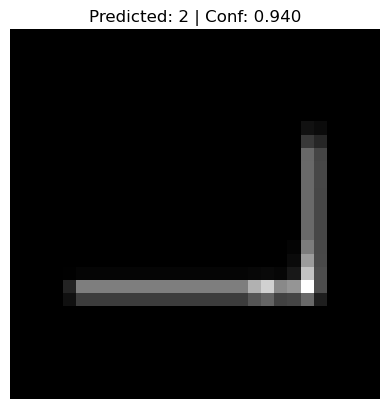

Cell 4 → Detected: 2
Probability: 0.940
-------------


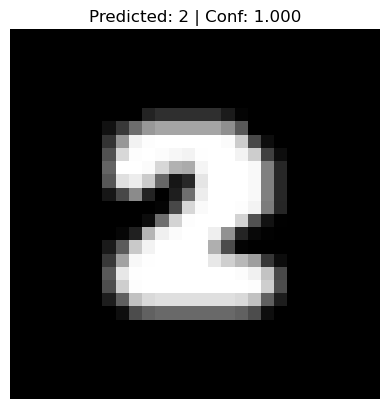

Cell 5 → Detected: 2
Probability: 1.000
-------------


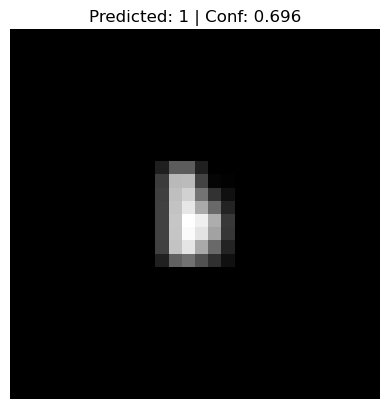

Cell 6 → Detected: 1
Probability: 0.696
-------------


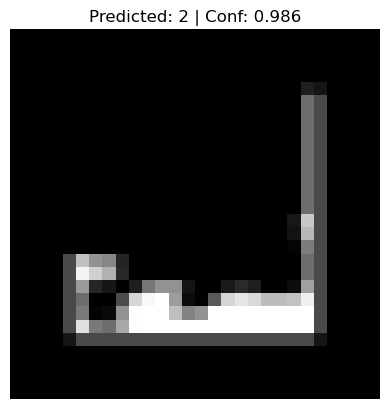

Cell 7 → Detected: 2
Probability: 0.986
-------------


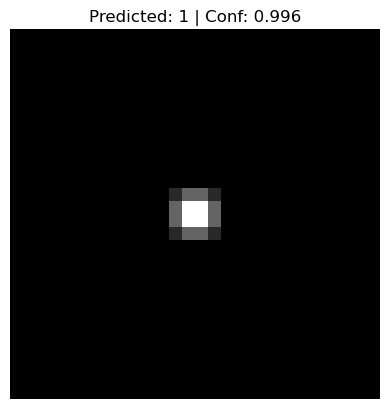

Cell 8 → Detected: 1
Probability: 0.996
-------------


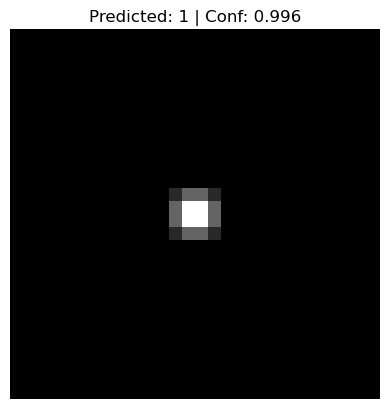

Cell 9 → Detected: 1
Probability: 0.996
-------------


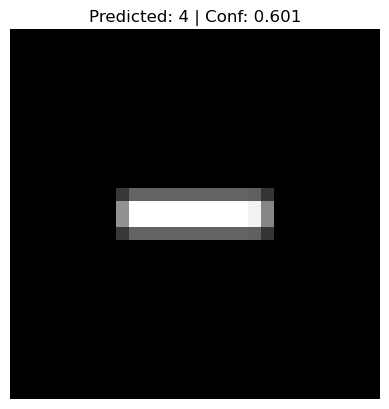

Cell 10 → Detected: 4
Probability: 0.601
-------------


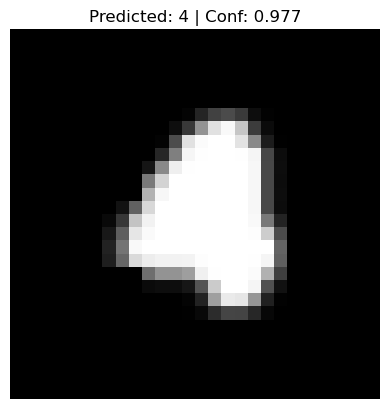

Cell 11 → Detected: 4
Probability: 0.977
-------------


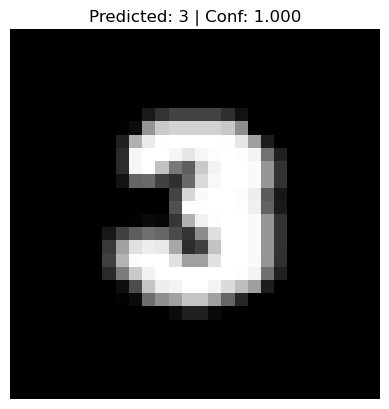

Cell 12 → Detected: 3
Probability: 1.000
-------------


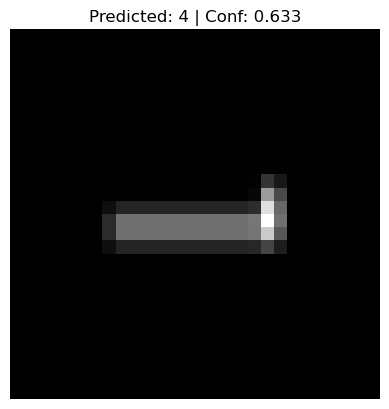

Cell 13 → Detected: 4
Probability: 0.633
-------------


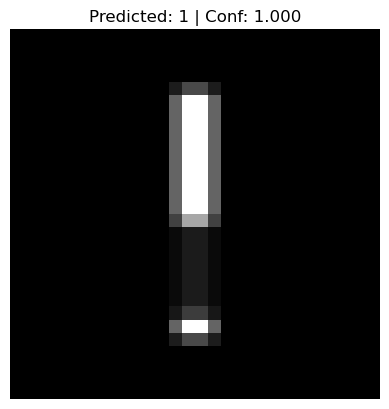

Cell 14 → Detected: 1
Probability: 1.000
-------------


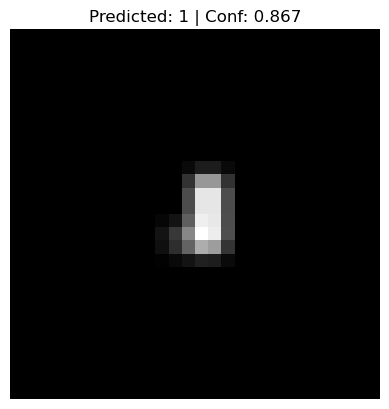

Cell 15 → Detected: 1
Probability: 0.867
-------------


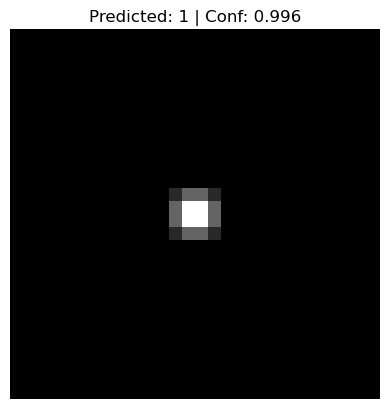

Cell 16 → Detected: 1
Probability: 0.996
-------------


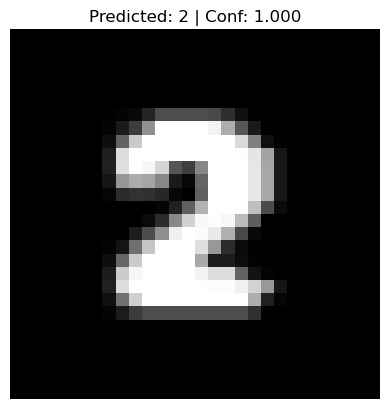

Cell 17 → Detected: 2
Probability: 1.000
-------------


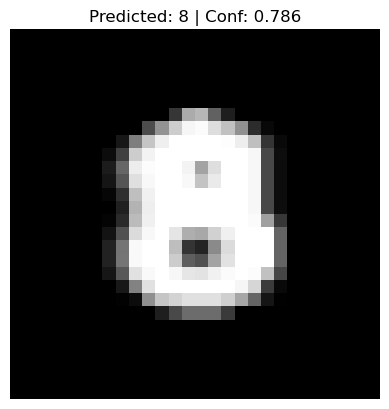

Cell 18 → Detected: 8
Probability: 0.786
-------------


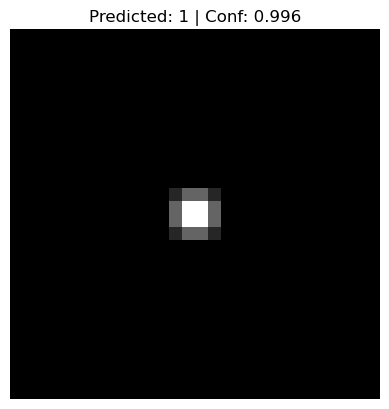

Cell 19 → Detected: 1
Probability: 0.996
-------------


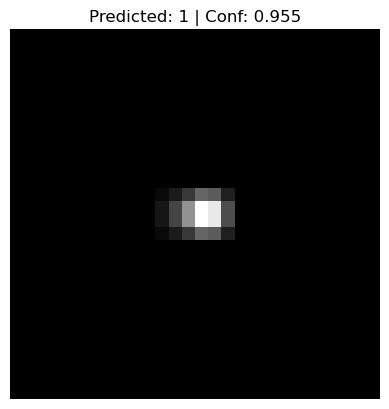

Cell 20 → Detected: 1
Probability: 0.955
-------------


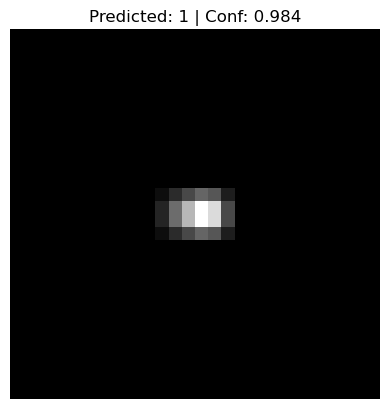

Cell 21 → Detected: 1
Probability: 0.984
-------------


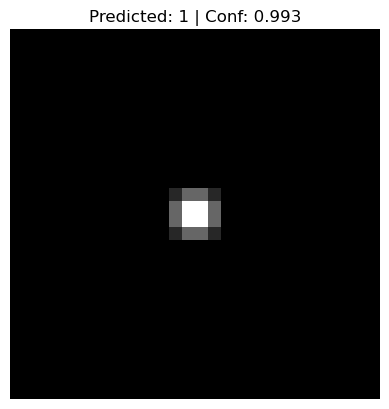

Cell 22 → Detected: 1
Probability: 0.993
-------------


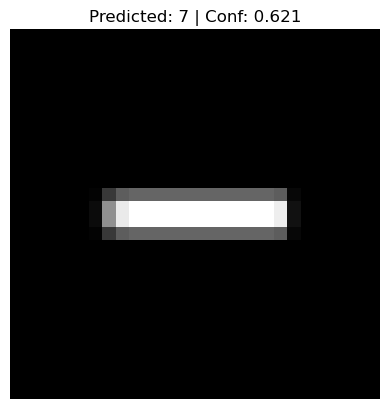

Cell 23 → Detected: 7
Probability: 0.621
-------------


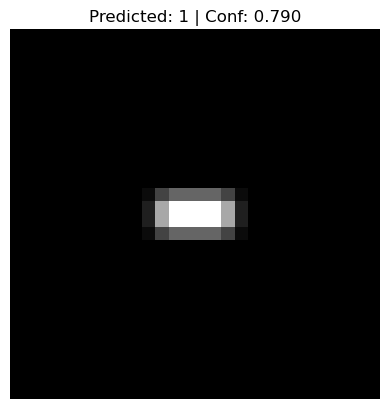

Cell 24 → Detected: 1
Probability: 0.790
-------------


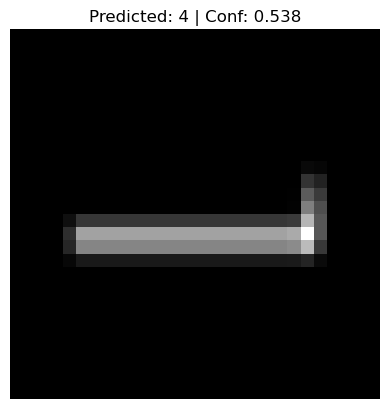

Cell 25 → Detected: 4
Probability: 0.538
-------------


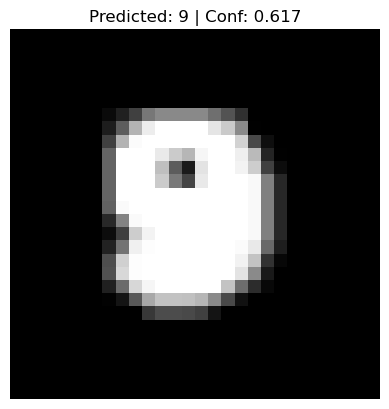

Cell 26 → Detected: 9
Probability: 0.617
-------------


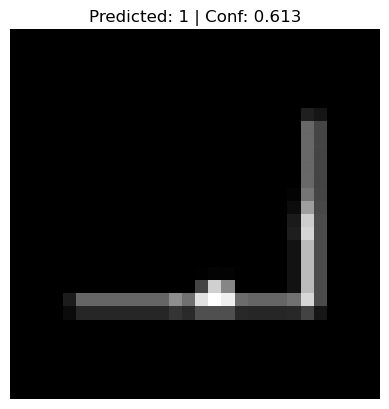

Cell 27 → Detected: 1
Probability: 0.613
-------------


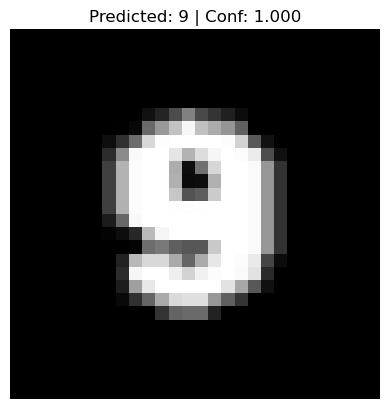

Cell 28 → Detected: 9
Probability: 1.000
-------------


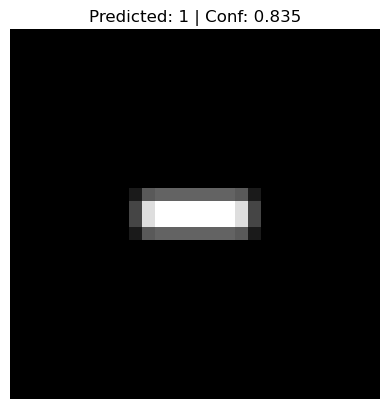

Cell 29 → Detected: 1
Probability: 0.835
-------------


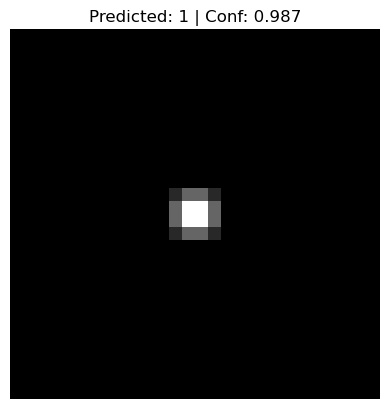

Cell 30 → Detected: 1
Probability: 0.987
-------------


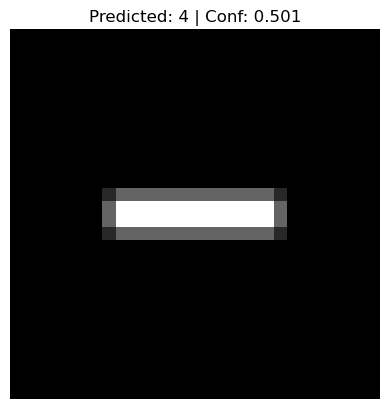

Cell 31 → Detected: 4
Probability: 0.501
-------------


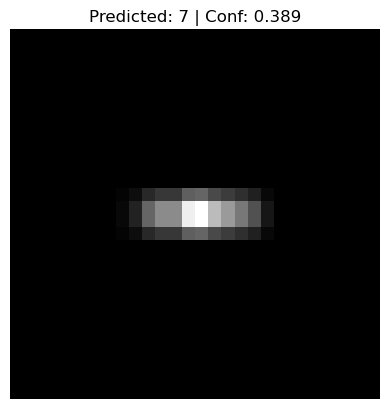

Cell 32 → Detected: 7
Probability: 0.389
-------------


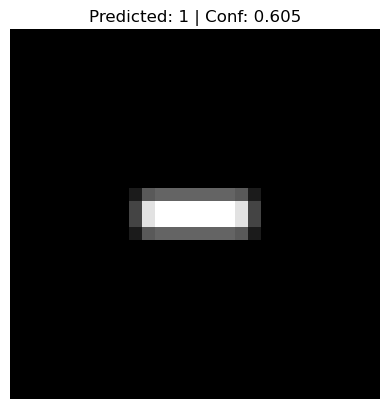

Cell 33 → Detected: 1
Probability: 0.605
-------------


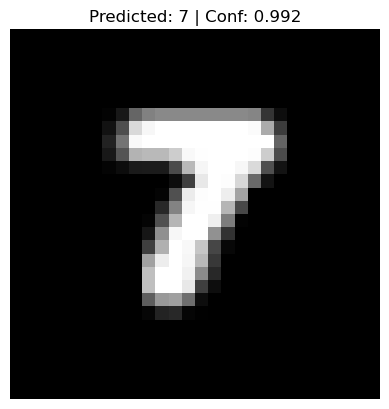

Cell 34 → Detected: 7
Probability: 0.992
-------------


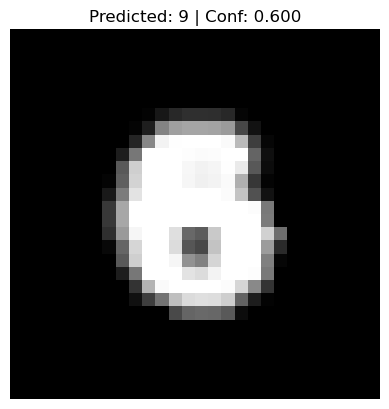

Cell 35 → Detected: 9
Probability: 0.600
-------------


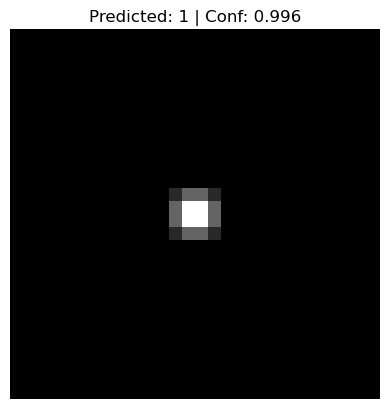

Cell 36 → Detected: 1
Probability: 0.996
-------------


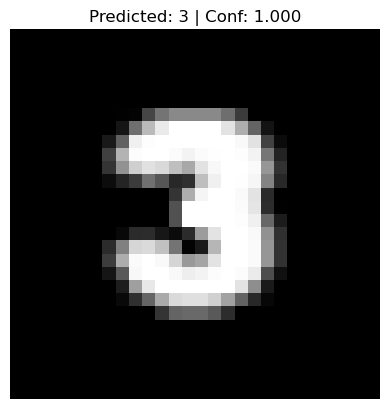

Cell 37 → Detected: 3
Probability: 1.000
-------------


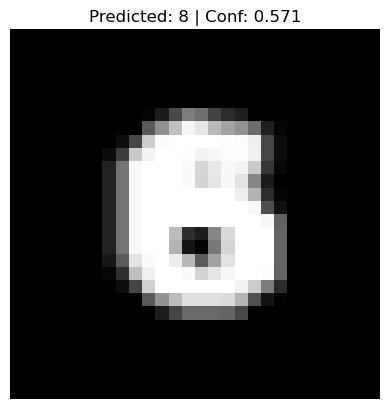

Cell 38 → Detected: 8
Probability: 0.571
-------------


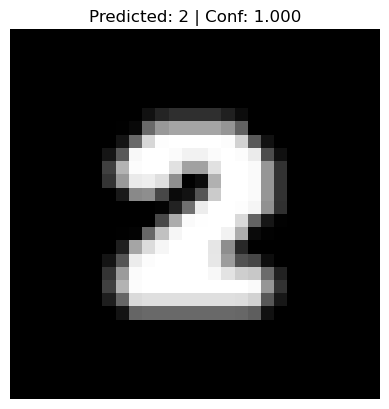

Cell 39 → Detected: 2
Probability: 1.000
-------------


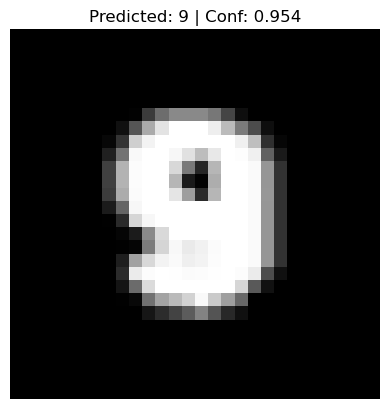

Cell 40 → Detected: 9
Probability: 0.954
-------------


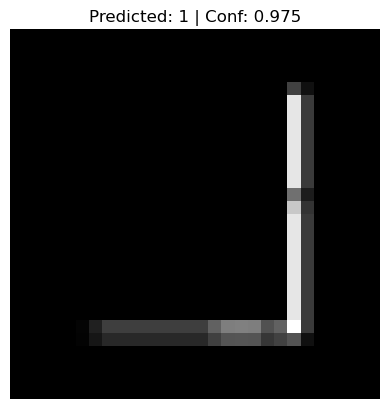

Cell 41 → Detected: 1
Probability: 0.975
-------------


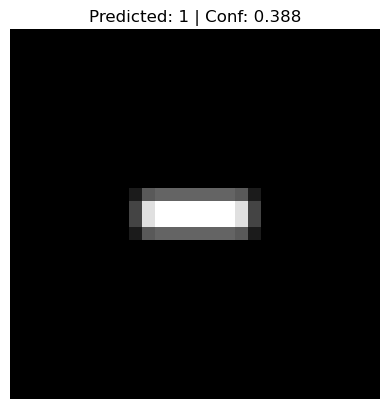

Cell 42 → Detected: 1
Probability: 0.388
-------------


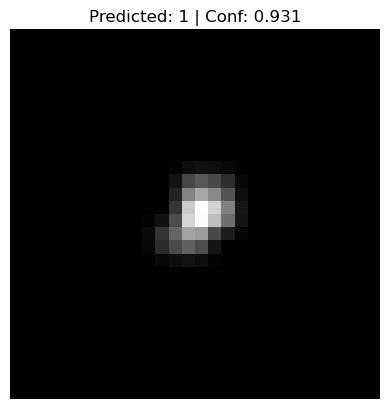

Cell 43 → Detected: 1
Probability: 0.931
-------------


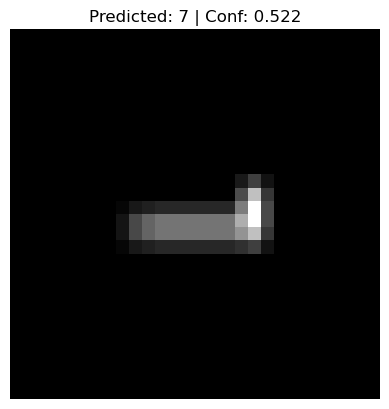

Cell 44 → Detected: 7
Probability: 0.522
-------------


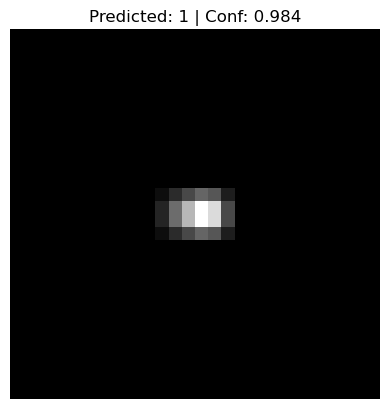

Cell 45 → Detected: 1
Probability: 0.984
-------------


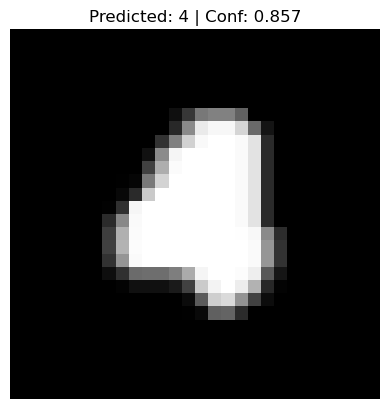

Cell 46 → Detected: 4
Probability: 0.857
-------------


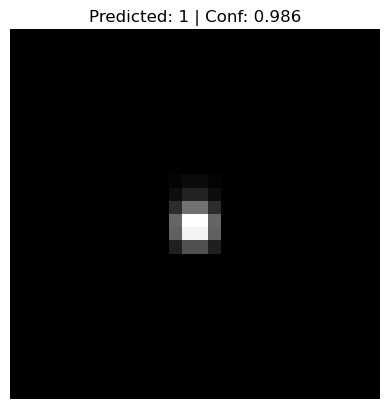

Cell 47 → Detected: 1
Probability: 0.986
-------------


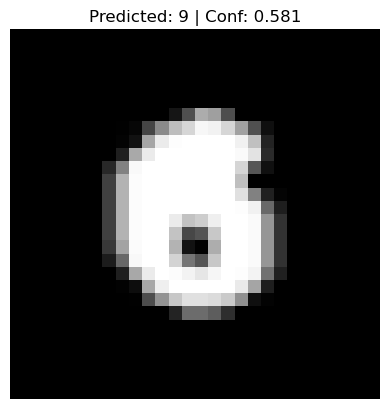

Cell 48 → Detected: 9
Probability: 0.581
-------------


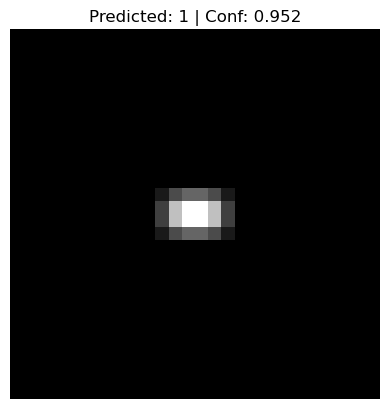

Cell 49 → Detected: 1
Probability: 0.952
-------------


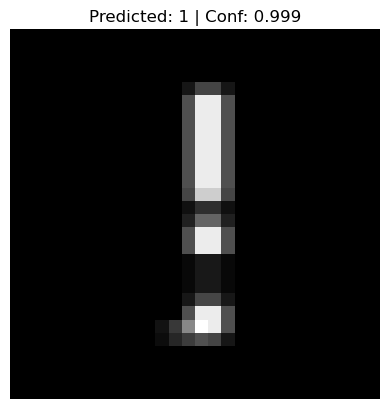

Cell 50 → Detected: 1
Probability: 0.999
-------------


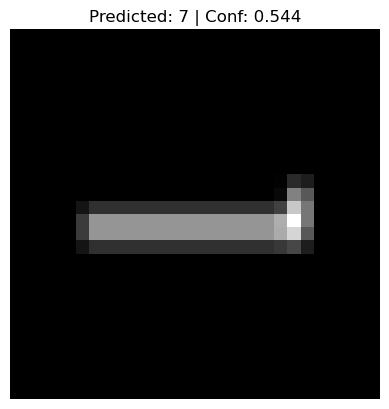

Cell 51 → Detected: 7
Probability: 0.544
-------------


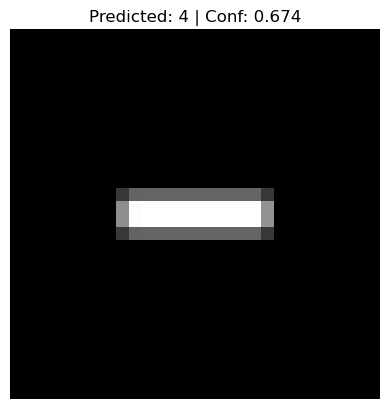

Cell 52 → Detected: 4
Probability: 0.674
-------------


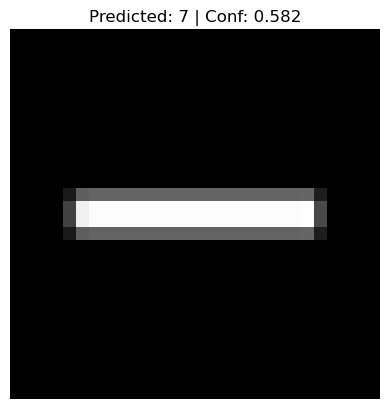

Cell 53 → Detected: 7
Probability: 0.582
-------------


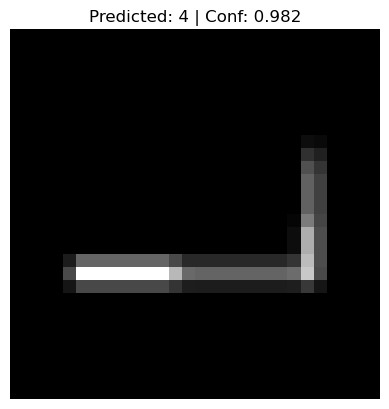

Cell 54 → Detected: 4
Probability: 0.982
-------------


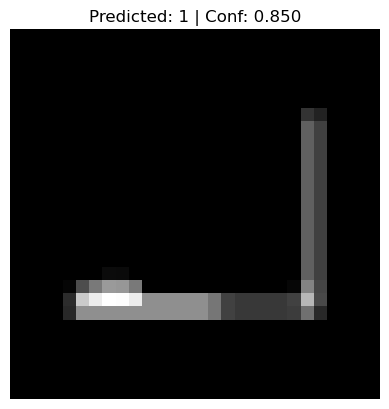

Cell 55 → Detected: 1
Probability: 0.850
-------------


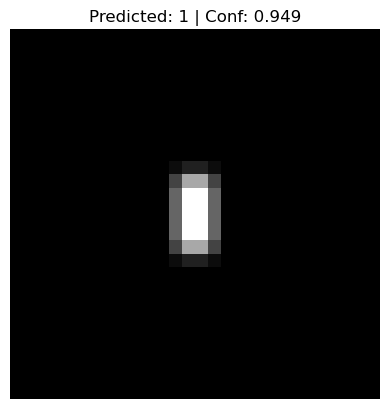

Cell 56 → Detected: 1
Probability: 0.949
-------------


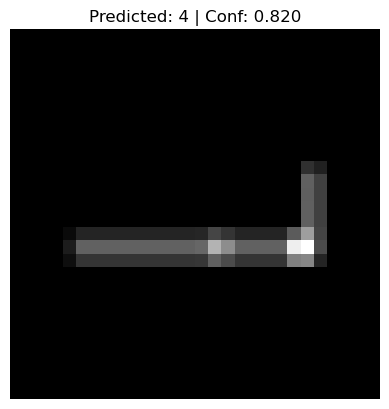

Cell 57 → Detected: 4
Probability: 0.820
-------------


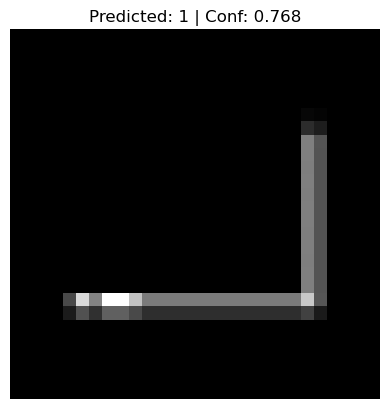

Cell 58 → Detected: 1
Probability: 0.768
-------------


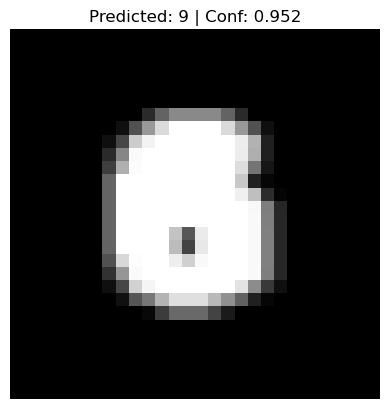

Cell 59 → Detected: 9
Probability: 0.952
-------------


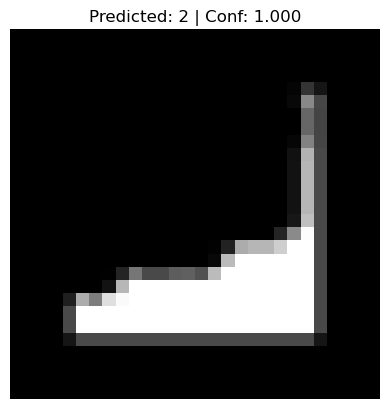

Cell 60 → Detected: 2
Probability: 1.000
-------------


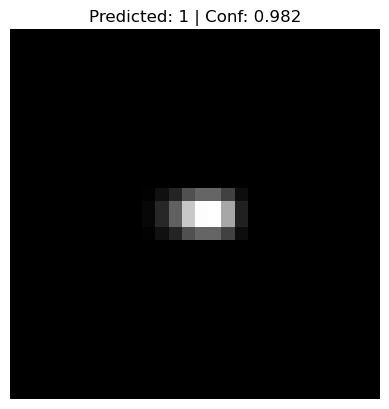

Cell 61 → Detected: 1
Probability: 0.982
-------------


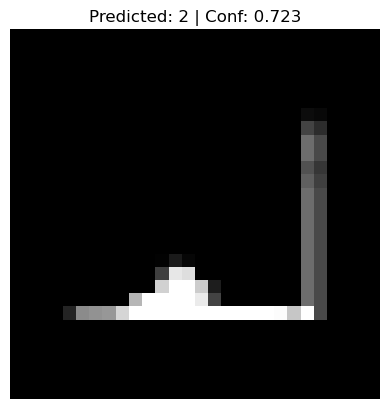

Cell 62 → Detected: 2
Probability: 0.723
-------------


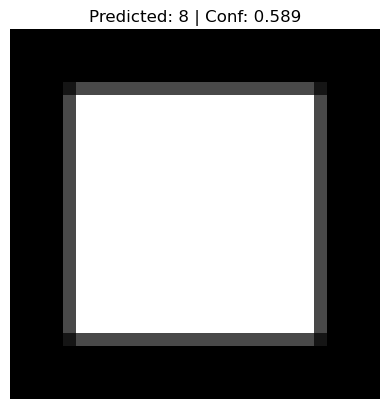

Cell 63 → Detected: 8
Probability: 0.589
-------------


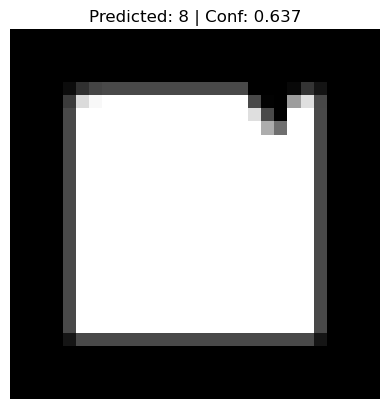

Cell 64 → Detected: 8
Probability: 0.637
-------------


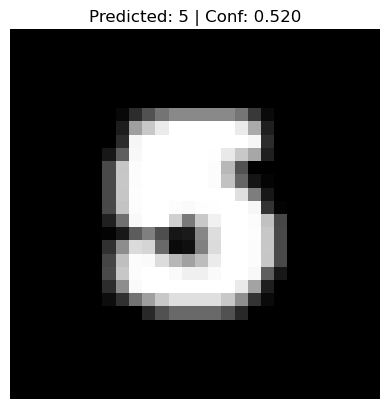

Cell 65 → Detected: 5
Probability: 0.520
-------------


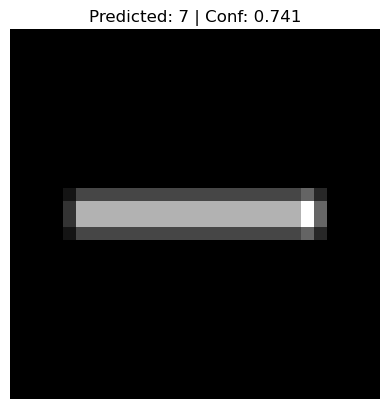

Cell 66 → Detected: 7
Probability: 0.741
-------------


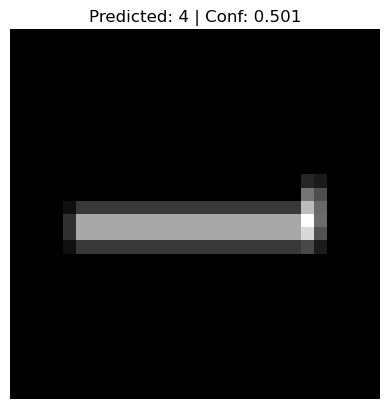

Cell 67 → Detected: 4
Probability: 0.501
-------------


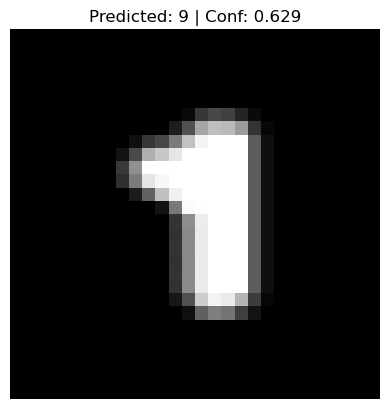

Cell 68 → Detected: 9
Probability: 0.629
-------------


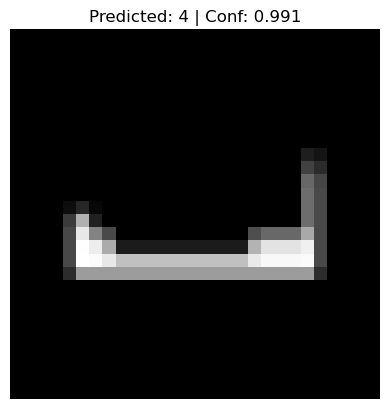

Cell 69 → Detected: 4
Probability: 0.991
-------------


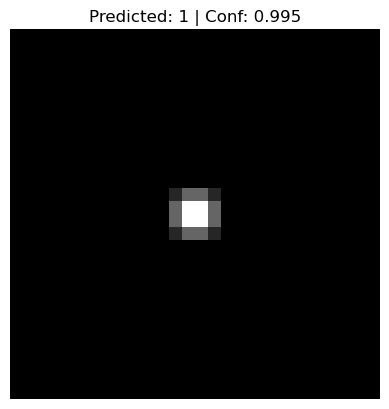

Cell 70 → Detected: 1
Probability: 0.995
-------------


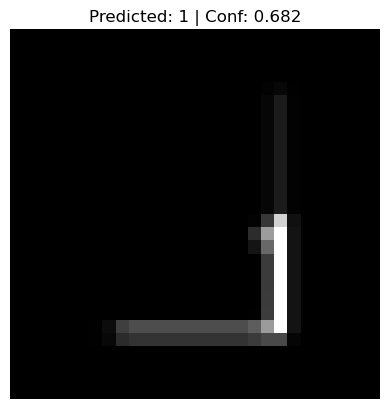

Cell 71 → Detected: 1
Probability: 0.682
-------------


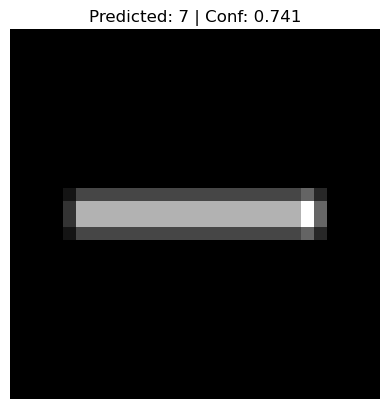

Cell 72 → Detected: 7
Probability: 0.741
-------------


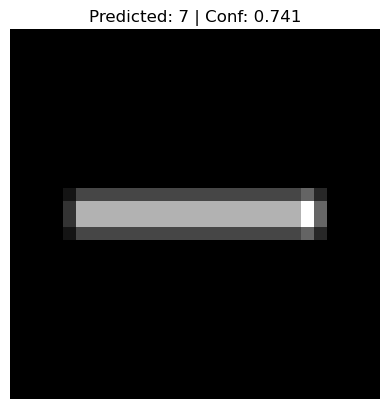

Cell 73 → Detected: 7
Probability: 0.741
-------------


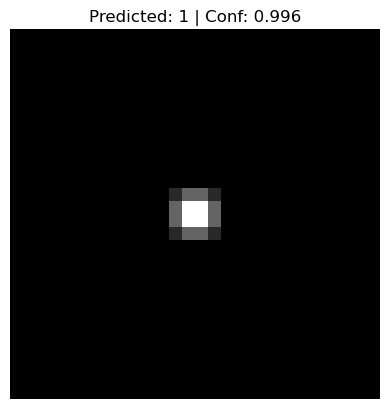

Cell 74 → Detected: 1
Probability: 0.996
-------------


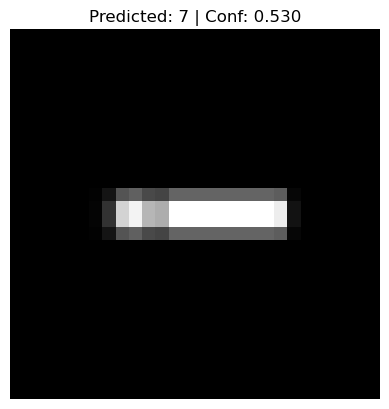

Cell 75 → Detected: 7
Probability: 0.530
-------------


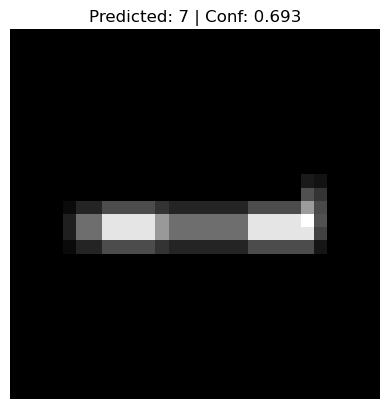

Cell 76 → Detected: 7
Probability: 0.693
-------------


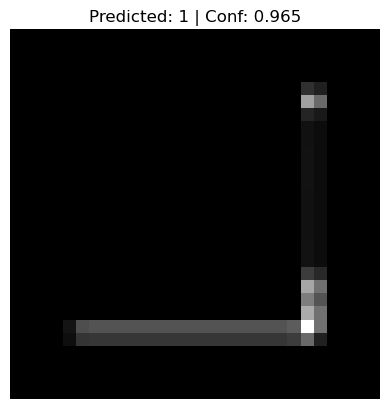

Cell 77 → Detected: 1
Probability: 0.965
-------------


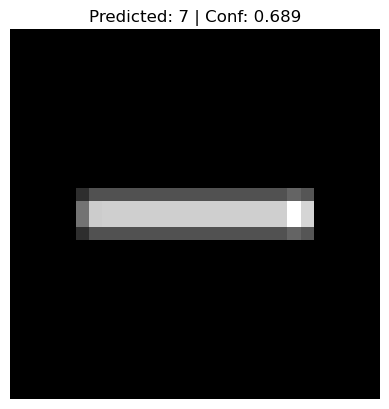

Cell 78 → Detected: 7
Probability: 0.689
-------------


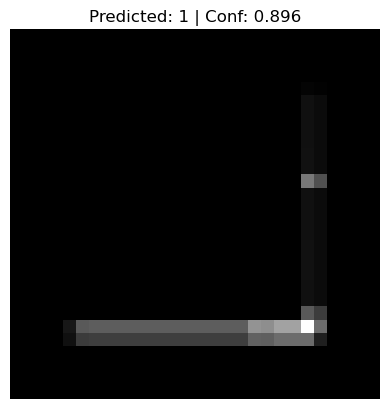

Cell 79 → Detected: 1
Probability: 0.896
-------------


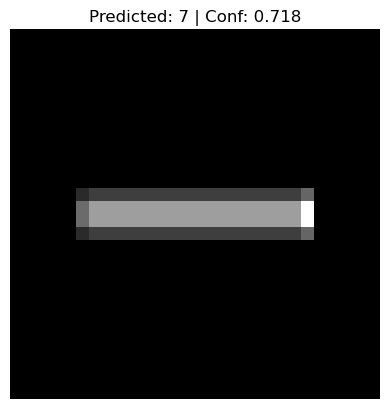

Cell 80 → Detected: 7
Probability: 0.718
-------------


In [19]:
IMG_SIZE = 28
CROP = 2

matrix = []
array = []
model = tf.keras.models.load_model('app/digit_model_centered.keras')
def center_digit(gray_img):
    _, thresh = cv2.threshold(gray_img, 20, 255, cv2.THRESH_BINARY)
    
    # kernel = np.ones((2, 2), np.uint8)
    # thresh = cv2.erode(thresh, kernel, iterations=1)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # coords = cv2.findNonZero(thresh)
    if len(contours) == 0:
        return cv2.resize(gray_img, (IMG_SIZE, IMG_SIZE))

    x, y, w, h = cv2.boundingRect(contours[0])
    digit_crop = gray_img[y:y+h, x:x+w]
    # plt.imshow(digit_crop, cmap='gray')
    # plt.title("Cropped Digit")
    # plt.axis('off')
    # plt.show()
    pad = 6  
    digit_crop = cv2.copyMakeBorder(
        digit_crop, pad, pad, pad, pad,
        cv2.BORDER_CONSTANT, value=0
    )

    centered = cv2.resize(digit_crop, (IMG_SIZE, IMG_SIZE))
    return centered


with open("app/solve/cells_data.json", "r") as f:
    data = json.load(f)

for i in range(81):
    img_path = f"app/digit_images/cell_{i}.png"

    img = cv2.imread(img_path)
    if img is None:
        print(f"Cell {i}: Image not found")
        continue
    img = img[CROP:-CROP, CROP:-CROP]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    centered = center_digit(gray)
    contours, _ = cv2.findContours(centered, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        print(f"Cell {i}: No contours found")
        array.append(0)
        data[f"cell_{i}"]['center'].append(0)
        if len(array) == 9:
            matrix.append(array)
            array = []  
        continue
    image_num = centered.astype('float32') / 255.0
    image_num = np.expand_dims(image_num, axis=-1)   
    image_num = np.expand_dims(image_num, axis=0)    

    prediction = model.predict(image_num, verbose=0)
    digit = np.argmax(prediction) + 1
    prob = np.max(prediction)
    data[f"cell_{i}"]['center'].append(1)

    plt.imshow(image_num[0].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    plt.title(f"Predicted: {digit} | Conf: {prob:.3f}")
    plt.axis('off')
    plt.show()

    print(f"Cell {i} → Detected: {digit}")
    print(f"Probability: {prob:.3f}")
    print("-------------")
    array.append(digit)
    if len(array) == 9:
        matrix.append(array)
        array = []

with open("cells_data.json", "w") as f:
    json.dump(data, f, indent=4)

In [20]:
matrix = np.array(matrix)
matrix

array([[3, 1, 9, 7, 2, 2, 1, 2, 1],
       [1, 4, 4, 3, 4, 1, 1, 1, 2],
       [8, 1, 1, 1, 1, 7, 1, 4, 9],
       [1, 9, 1, 1, 4, 7, 1, 7, 9],
       [1, 3, 8, 2, 9, 1, 1, 1, 7],
       [1, 4, 1, 9, 1, 1, 7, 4, 7],
       [4, 1, 1, 4, 1, 9, 2, 1, 2],
       [8, 8, 5, 7, 4, 9, 4, 1, 1],
       [7, 7, 1, 7, 7, 1, 7, 1, 7]], dtype=int64)

In [127]:
def solve_sudoku(board):
    empty = find_empty(board)
    if not empty:
        return True  

    row, col = empty

    for num in range(1, 10):
        if is_valid(board, row, col, num):
            board[row][col] = num

            if solve_sudoku(board):
                return True

            board[row][col] = 0  

    return False  


def find_empty(board):
    for i in range(9):
        for j in range(9):
            if board[i][j] == 0:
                return (i, j)
    return None


def is_valid(board, row, col, num):
    if num in board[row]:
        return False

    if num in [board[i][col] for i in range(9)]:
        return False

    box_row, box_col = 3 * (row // 3), 3 * (col // 3)
    for i in range(box_row, box_row + 3):
        for j in range(box_col, box_col + 3):
            if board[i][j] == num:
                return False

    return True


def print_board(board):
    for i, row in enumerate(board):
        if i % 3 == 0 and i != 0:
            print("------+-------+------")
        row_str = ""
        for j, val in enumerate(range(9)):
            if j % 3 == 0 and j != 0:
                row_str += " | "
            row_str += str(row[j]) + " "
        print(row_str)

In [128]:
board = matrix
print("Before:")
print_board(board)

if solve_sudoku(board):
    print("\nSolved:")
    print_board(board)
else:
    print("No solution exists — likely a misread digit")

Before:
0 0 2  | 0 5 0  | 0 0 6 
0 0 0  | 0 0 4  | 0 7 0 
1 0 8  | 0 9 0  | 0 0 0 
------+-------+------
0 0 0  | 7 0 6  | 0 8 0 
7 0 6  | 0 0 0  | 2 0 4 
0 8 0  | 5 0 2  | 0 0 0 
------+-------+------
0 0 0  | 0 1 0  | 3 0 8 
0 9 0  | 4 0 0  | 0 0 0 
8 0 0  | 0 2 0  | 4 0 0 

Solved:
4 7 2  | 8 5 1  | 9 3 6 
3 5 9  | 2 6 4  | 8 7 1 
1 6 8  | 3 9 7  | 5 4 2 
------+-------+------
5 2 4  | 7 3 6  | 1 8 9 
7 3 6  | 1 8 9  | 2 5 4 
9 8 1  | 5 4 2  | 7 6 3 
------+-------+------
6 4 7  | 9 1 5  | 3 2 8 
2 9 3  | 4 7 8  | 6 1 5 
8 1 5  | 6 2 3  | 4 9 7 


In [129]:
board = board.reshape(1, 81)
board

array([[4, 7, 2, 8, 5, 1, 9, 3, 6, 3, 5, 9, 2, 6, 4, 8, 7, 1, 1, 6, 8, 3,
        9, 7, 5, 4, 2, 5, 2, 4, 7, 3, 6, 1, 8, 9, 7, 3, 6, 1, 8, 9, 2, 5,
        4, 9, 8, 1, 5, 4, 2, 7, 6, 3, 6, 4, 7, 9, 1, 5, 3, 2, 8, 2, 9, 3,
        4, 7, 8, 6, 1, 5, 8, 1, 5, 6, 2, 3, 4, 9, 7]])

In [130]:
with open("cells_data.json", "r") as f:
    loaded_data = json.load(f)
loaded_data

{'cell_0': {'center': [43, 42, 0]},
 'cell_1': {'center': [88, 43, 0]},
 'cell_2': {'center': [134, 43, 1]},
 'cell_3': {'center': [180, 42, 0]},
 'cell_4': {'center': [226, 43, 1]},
 'cell_5': {'center': [272, 42, 0]},
 'cell_6': {'center': [318, 43, 0]},
 'cell_7': {'center': [364, 43, 0]},
 'cell_8': {'center': [409, 43, 1]},
 'cell_9': {'center': [42, 88, 0]},
 'cell_10': {'center': [88, 88, 0]},
 'cell_11': {'center': [134, 88, 0]},
 'cell_12': {'center': [180, 88, 0]},
 'cell_13': {'center': [226, 88, 0]},
 'cell_14': {'center': [272, 88, 1]},
 'cell_15': {'center': [318, 88, 0]},
 'cell_16': {'center': [364, 88, 1]},
 'cell_17': {'center': [409, 88, 0]},
 'cell_18': {'center': [42, 134, 1]},
 'cell_19': {'center': [88, 134, 0]},
 'cell_20': {'center': [134, 134, 1]},
 'cell_21': {'center': [180, 134, 0]},
 'cell_22': {'center': [226, 134, 1]},
 'cell_23': {'center': [272, 134, 0]},
 'cell_24': {'center': [318, 134, 0]},
 'cell_25': {'center': [364, 134, 0]},
 'cell_26': {'center

In [ ]:
img = cv2.imread("sample_input_output/images/grid.png")
font = cv2.FONT_HERSHEY_SIMPLEX
i = 0
for key, value in loaded_data.items():
    print(f"{key}: {value}")
    if value["center"][2] == 0:
        cv2.putText(img,str(board[0][i]),(value["center"][0],value["center"][1]), font, 0.8,(255,0,0),2,cv2.LINE_AA)
    i = i + 1
cv2.imshow("Solved Sudoku", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

cell_0: {'center': [43, 42, 0]}
cell_1: {'center': [88, 43, 0]}
cell_2: {'center': [134, 43, 1]}
cell_3: {'center': [180, 42, 0]}
cell_4: {'center': [226, 43, 1]}
cell_5: {'center': [272, 42, 0]}
cell_6: {'center': [318, 43, 0]}
cell_7: {'center': [364, 43, 0]}
cell_8: {'center': [409, 43, 1]}
cell_9: {'center': [42, 88, 0]}
cell_10: {'center': [88, 88, 0]}
cell_11: {'center': [134, 88, 0]}
cell_12: {'center': [180, 88, 0]}
cell_13: {'center': [226, 88, 0]}
cell_14: {'center': [272, 88, 1]}
cell_15: {'center': [318, 88, 0]}
cell_16: {'center': [364, 88, 1]}
cell_17: {'center': [409, 88, 0]}
cell_18: {'center': [42, 134, 1]}
cell_19: {'center': [88, 134, 0]}
cell_20: {'center': [134, 134, 1]}
cell_21: {'center': [180, 134, 0]}
cell_22: {'center': [226, 134, 1]}
cell_23: {'center': [272, 134, 0]}
cell_24: {'center': [318, 134, 0]}
cell_25: {'center': [364, 134, 0]}
cell_26: {'center': [409, 134, 0]}
cell_27: {'center': [42, 180, 0]}
cell_28: {'center': [88, 180, 0]}
cell_29: {'center': [